In [426]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split as sklearn_train_test_split
from sklearn.model_selection import KFold
from matplotlib.colors import ListedColormap

In [427]:
seed = 42
np.random.seed(seed)
print("seed is", seed)

seed is 42


In [428]:
# TASK 0: EDA & PREPROCESSING

In [429]:
#1. Load each dataset. Handle missing values (drop/justify). Print shapes and class/target summaries.

In [430]:
# Wine Quality Dataset

In [431]:
# load the dataset
wine_df = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",sep=";")
wine_df.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [432]:
# check missing values
print("Missing values:")
print(wine_df.isnull().sum())


Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [433]:
# dataset shape
print("Shape of wine dataset:", wine_df.shape)

Shape of wine dataset: (1599, 12)


In [434]:
# target variable
print("Quality column summary:")
print(wine_df["quality"].describe())

Quality column summary:
count    1599.000000
mean        5.636023
std         0.807569
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64


In [435]:
#class summary
print("class Summary")
print(wine_df["quality"].value_counts())

class Summary
quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64


In [436]:
# Banknote Dataset

In [437]:
# column names
bank_cols = ["variance", "skewness", "curtosis", "entropy", "class"]

# load dataset
bank_df = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt",
                       header=None, names=bank_cols)
bank_df.head(5)

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [438]:
# check missing values
print("Missing values:")
print(bank_df.isnull().sum())

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


In [439]:
# dataset shape
print("Shape of dataset:", bank_df.shape)

Shape of dataset: (1372, 5)


In [440]:
# target summary
print("class column summary: ")
print(bank_df["class"].describe())

class column summary: 
count    1372.000000
mean        0.444606
std         0.497103
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: class, dtype: float64


In [441]:
#class summary
print("class Summary")
print(bank_df["class"].value_counts())

class Summary
class
0    762
1    610
Name: count, dtype: int64


In [442]:
#Iris Dataset

In [443]:
# column names
iris_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

# load dataset
iris_df = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data",
                      names=iris_cols)
iris_df.head(5)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [444]:
# check missing values
print("Missing values: ")
print(iris_df.isnull().sum())

Missing values: 
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [445]:
# dataset shape
print("Shape of dataset:", iris_df.shape)

Shape of dataset: (150, 5)


In [446]:
# target column summary
print("Species column summary :")
print(iris_df["species"].describe())


Species column summary :
count             150
unique              3
top       Iris-setosa
freq               50
Name: species, dtype: object


In [447]:
#class summary
print("class Summary")
print(iris_df["species"].value_counts())

class Summary
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [448]:
# 2. Compute basic stats (mean/median/std/min/max) for numeric features.


In [449]:
# Basic Stats for Numeric Features of Wine data set

In [450]:
target_col = "quality"
feature_cols = wine_df.drop(columns=[target_col]).select_dtypes(include=['number']).columns

print(" Basic Stats for Numeric Features of Wine data set")
for col in feature_cols:
    print("Column:", col)
    print("Mean:", wine_df[col].mean())
    print("Median:", wine_df[col].median())
    print("Std:", wine_df[col].std())
    print("Min:", wine_df[col].min())
    print("Max:", wine_df[col].max())
    print("\n")

 Basic Stats for Numeric Features of Wine data set
Column: fixed acidity
Mean: 8.31963727329581
Median: 7.9
Std: 1.7410963181277006
Min: 4.6
Max: 15.9


Column: volatile acidity
Mean: 0.5278205128205128
Median: 0.52
Std: 0.17905970415353498
Min: 0.12
Max: 1.58


Column: citric acid
Mean: 0.2709756097560976
Median: 0.26
Std: 0.19480113740531785
Min: 0.0
Max: 1.0


Column: residual sugar
Mean: 2.53880550343965
Median: 2.2
Std: 1.4099280595072805
Min: 0.9
Max: 15.5


Column: chlorides
Mean: 0.08746654158849279
Median: 0.079
Std: 0.047065302010090154
Min: 0.012
Max: 0.611


Column: free sulfur dioxide
Mean: 15.874921826141339
Median: 14.0
Std: 10.46015696980973
Min: 1.0
Max: 72.0


Column: total sulfur dioxide
Mean: 46.46779237023139
Median: 38.0
Std: 32.89532447829901
Min: 6.0
Max: 289.0


Column: density
Mean: 0.9967466791744841
Median: 0.99675
Std: 0.0018873339538425559
Min: 0.99007
Max: 1.00369


Column: pH
Mean: 3.3111131957473416
Median: 3.31
Std: 0.15438646490354266
Min: 2.74
Max: 4

In [451]:
# Basic Stats for Numeric Features of Banknote data set

In [452]:

target_col = "class"
feature_cols = bank_df.drop(columns=[target_col]).select_dtypes(include=['number']).columns

print(" Basic Stats for Numeric Features of Wine data set")
for col in feature_cols:
    print("Column:", col)
    print("Mean:", bank_df[col].mean())
    print("Median:", bank_df[col].median())
    print("Std:", bank_df[col].std())
    print("Min:", bank_df[col].min())
    print("Max:", bank_df[col].max())
    print("\n")

 Basic Stats for Numeric Features of Wine data set
Column: variance
Mean: 0.4337352570699707
Median: 0.49617999999999995
Std: 2.842762586278562
Min: -7.0421
Max: 6.8248


Column: skewness
Mean: 1.9223531206393585
Median: 2.31965
Std: 5.869046743695522
Min: -13.7731
Max: 12.9516


Column: curtosis
Mean: 1.3976271172667638
Median: 0.61663
Std: 4.310030090106595
Min: -5.2861
Max: 17.9274


Column: entropy
Mean: -1.1916565200437317
Median: -0.58665
Std: 2.1010131373596095
Min: -8.5482
Max: 2.4495




In [453]:
# Basic Stats for Numeric Features of Iris data set

In [454]:
target_col = "species"
feature_cols = iris_df.drop(columns=[target_col]).select_dtypes(include=['number']).columns

print(" Basic Stats for Numeric Features of Wine data set")
for col in feature_cols:
    print("Column:", col)
    print("Mean:", iris_df[col].mean())
    print("Median:", iris_df[col].median())
    print("Std:", iris_df[col].std())
    print("Min:", iris_df[col].min())
    print("Max:", iris_df[col].max())
    print("\n")

 Basic Stats for Numeric Features of Wine data set
Column: sepal_length
Mean: 5.843333333333334
Median: 5.8
Std: 0.8280661279778629
Min: 4.3
Max: 7.9


Column: sepal_width
Mean: 3.0540000000000003
Median: 3.0
Std: 0.4335943113621737
Min: 2.0
Max: 4.4


Column: petal_length
Mean: 3.758666666666666
Median: 4.35
Std: 1.7644204199522617
Min: 1.0
Max: 6.9


Column: petal_width
Mean: 1.1986666666666668
Median: 1.3
Std: 0.7631607417008414
Min: 0.1
Max: 2.5




In [455]:
#3. Train/test split once per dataset (80/20, fixed seeds). Standardize using train stats only.

In [456]:
# Common Utilities

In [457]:
def standardize_fit(X_train, eps=1e-12):
    # calculate mean and std of columns
    mean = np.mean(X_train, axis=0)
    std = np.std(X_train, axis=0)

    # fix very small std to avoid divide by zero
    std = np.where(std < eps, eps, std)

    # standardize
    X_scaled = (X_train - mean) / std

    return X_scaled, mean, std

In [458]:
def standardize_apply(X, mean, std, eps=1e-12):
    # avoid divide by zero
    std = np.where(std < eps, eps, std)

    # standardize using given mean and std
    X_scaled = (X - mean) / std

    return X_scaled

In [459]:
def train_test_split_idx(n, test_size=0.2, seed=0):
    # create indices from 0 to n-1
    indices = np.arange(n)

    # split indices into train and test
    train_idx, test_idx = sklearn_train_test_split(
        indices, test_size=test_size, random_state=seed
    )

    return train_idx, test_idx

In [460]:
# Wine Quality Dataset

In [461]:
# separate features and target
X_wine = wine_df.drop("quality", axis=1).values
y_wine = wine_df["quality"].values

# split into train and test sets
X_wine_train, X_wine_test, y_wine_train, y_wine_test = sklearn_train_test_split(
    X_wine, y_wine, test_size=0.2, random_state=seed
)

# standardize train data
X_wine_train_std, wine_mean, wine_std = standardize_fit(X_wine_train)

# apply same standardization to test data
X_wine_test_std = standardize_apply(X_wine_test, wine_mean, wine_std)

# print shapes
print("Wine data split and standardized.")
print("Train shape:", X_wine_train_std.shape)
print("Test shape:", X_wine_test_std.shape)


Wine data split and standardized.
Train shape: (1279, 11)
Test shape: (320, 11)


In [462]:
# Bank Note Dataset

In [463]:
# separate features and target
X_bank = bank_df.drop("class", axis=1).values
y_bank = bank_df["class"].values

# split into train and test sets (stratified)
X_bank_train, X_bank_test, y_bank_train, y_bank_test = sklearn_train_test_split(
    X_bank, y_bank, test_size=0.2, random_state=seed, stratify=y_bank
)

# standardize train data
X_bank_train_std, bank_mean, bank_std = standardize_fit(X_bank_train)

# apply same standardization to test data
X_bank_test_std = standardize_apply(X_bank_test, bank_mean, bank_std)

# print shapes
print("Banknote data split and standardized.")
print("Train shape:", X_bank_train_std.shape)
print("Test shape:", X_bank_test_std.shape)

Banknote data split and standardized.
Train shape: (1097, 4)
Test shape: (275, 4)


In [464]:
# Iris Dataset

In [465]:
# map species to numeric IDs
species_map = {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
iris_df['species_id'] = iris_df['species'].map(species_map)

# separate features and target
X_iris = iris_df.drop(['species', 'species_id'], axis=1).values
y_iris = iris_df['species_id'].values

# split into train and test sets (stratified)
X_iris_train, X_iris_test, y_iris_train, y_iris_test = sklearn_train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=seed, stratify=y_iris
)

# print shapes
print("\nIris data split.")
print("Train shape:", X_iris_train.shape)
print("Test shape:", X_iris_test.shape)



Iris data split.
Train shape: (120, 4)
Test shape: (30, 4)


In [466]:
#4. Produce 2–3 plots per dataset (histograms / pairwise scatter / boxplots) and describe any outliers/skew.

In [467]:
# Wine data

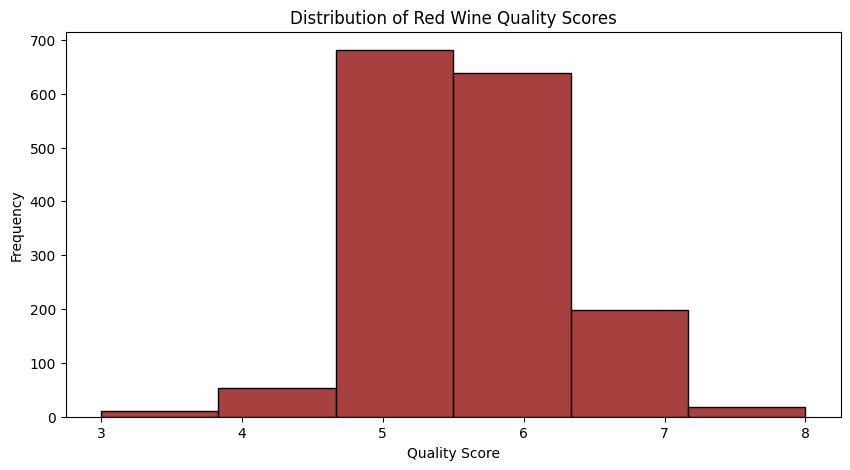

In [468]:
plt.figure(figsize=(10, 5))
sns.histplot(
    wine_df['quality'],
    bins=len(wine_df['quality'].unique()),
    kde=False,
    color='darkred'
)
plt.title('Distribution of Red Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Frequency')
plt.show()

In [469]:
# Analysis
print("Plot Analysis:")
print("- Most wine quality scores are 5 and 6.")
print("- Distribution is roughly symmetric, slightly right-skewed.")
print("- Very few wines have extreme scores like 3 or 8 (possible outliers).")

Plot Analysis:
- Most wine quality scores are 5 and 6.
- Distribution is roughly symmetric, slightly right-skewed.
- Very few wines have extreme scores like 3 or 8 (possible outliers).


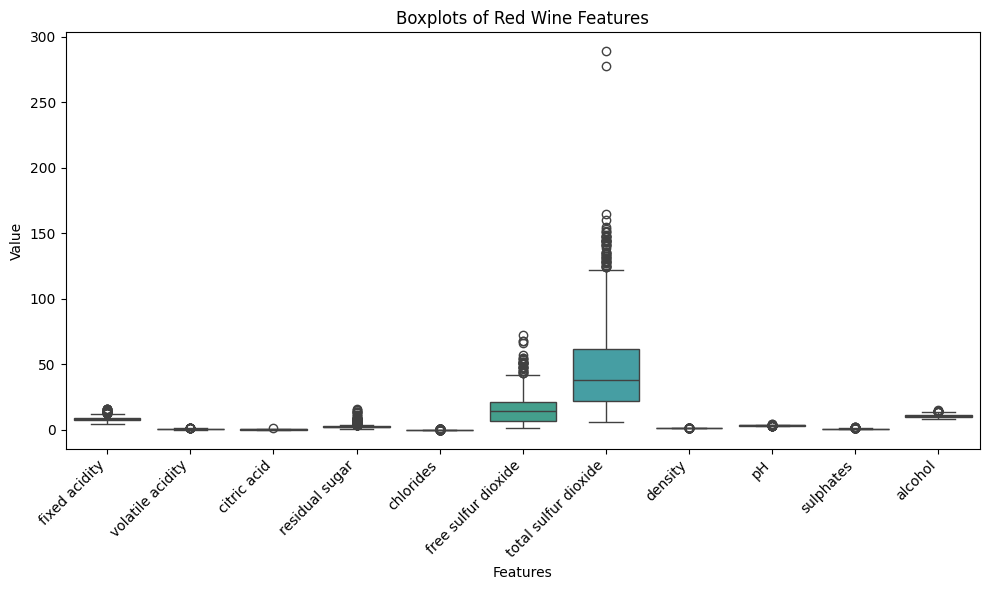

In [470]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=wine_df.drop('quality', axis=1))
plt.title('Boxplots of Red Wine Features')
plt.ylabel('Value')
plt.xlabel('Features')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [471]:
# Analysis
print("Plot Analysis:")
print("- Features have different scales, so standardization is necessary before modeling.")
print("- Several features, like 'residual sugar' and 'chlorides', show clear outliers.")
print("- Most features have a fairly symmetric distribution, but a few are right-skewed.")

Plot Analysis:
- Features have different scales, so standardization is necessary before modeling.
- Several features, like 'residual sugar' and 'chlorides', show clear outliers.
- Most features have a fairly symmetric distribution, but a few are right-skewed.


In [472]:
# Bank Data

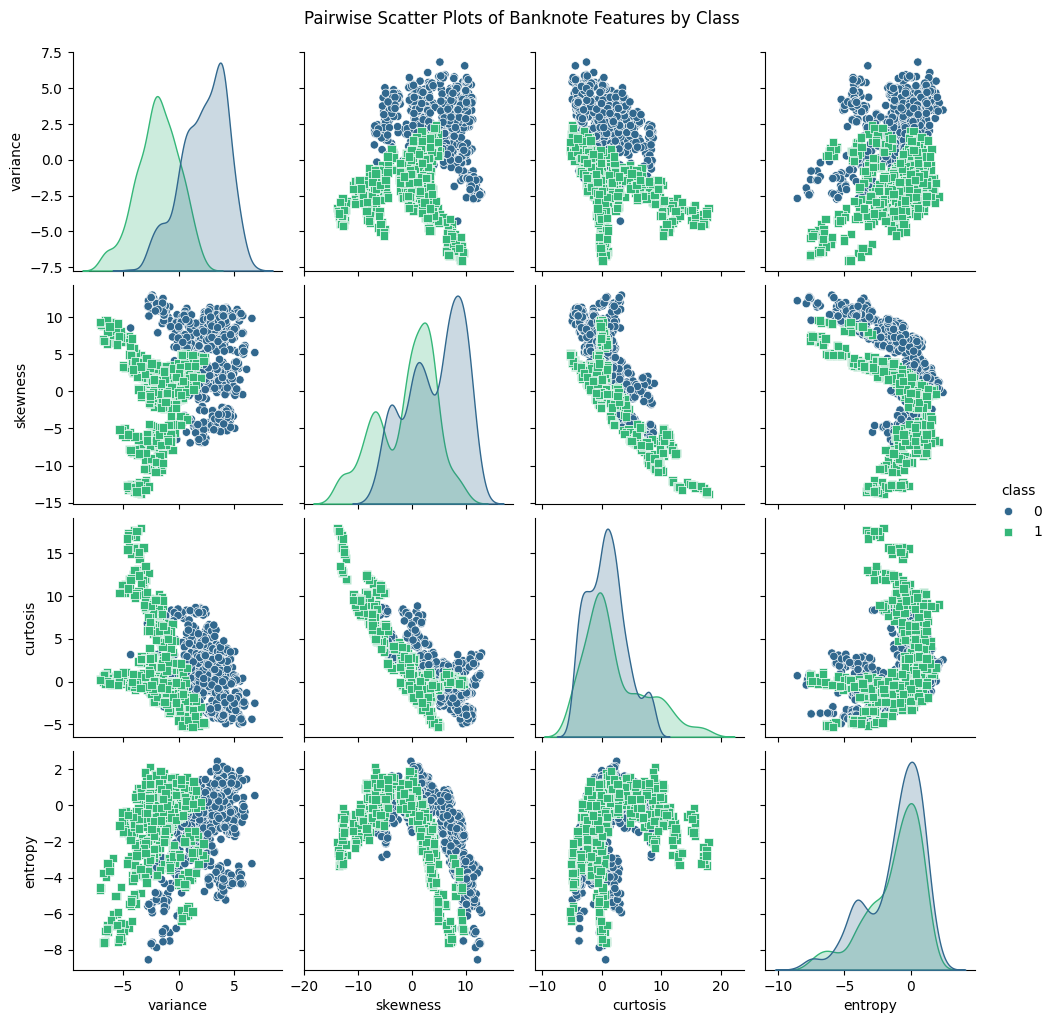

In [473]:
sns.pairplot(bank_df, hue='class', palette='viridis', markers=["o", "s"])
plt.suptitle('Pairwise Scatter Plots of Banknote Features by Class', y=1.02)
plt.show()

In [474]:
# Analysis
print("Plot Analysis:")
print("- The scatter plots show clear separation between the two classes.")
print("- Especially in combinations involving 'variance' and 'skewness', the classes form distinct clusters.")
print("- This suggests that even simple linear models may perform well.")

Plot Analysis:
- The scatter plots show clear separation between the two classes.
- Especially in combinations involving 'variance' and 'skewness', the classes form distinct clusters.
- This suggests that even simple linear models may perform well.


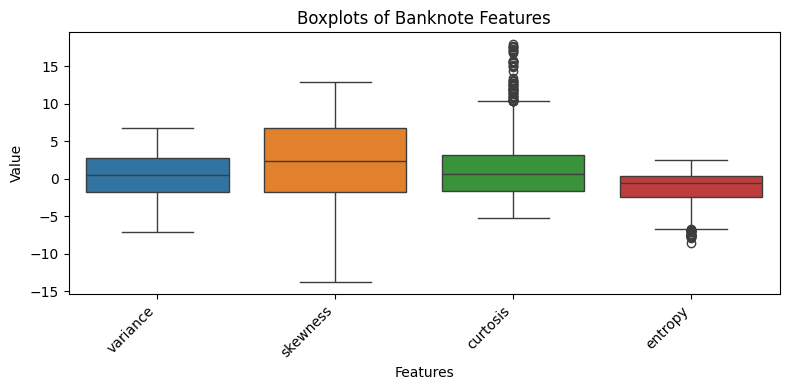

In [475]:
# Boxplot of features
plt.figure(figsize=(8, 4))
sns.boxplot(data=bank_df.drop('class', axis=1))
plt.title('Boxplots of Banknote Features')
plt.ylabel('Value')
plt.xlabel('Features')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [476]:
print("Plot Analysis:\nSome extreme outliers exist, especially in 'variance' and 'entropy'.")

Plot Analysis:
Some extreme outliers exist, especially in 'variance' and 'entropy'.


In [477]:
#Iris data

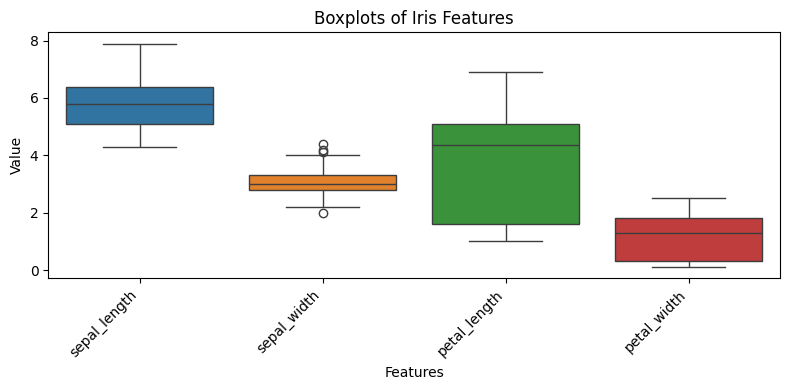

In [478]:
# Boxplot of features
plt.figure(figsize=(8, 4))
sns.boxplot(data=iris_df.drop(['species', 'species_id'], axis=1))
plt.title('Boxplots of Iris Features')
plt.ylabel('Value')
plt.xlabel('Features')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [479]:
print("Plot Analysis:\nOutliers are minor, but petal-related features have clear separation, "
      "which may help in classification.")

Plot Analysis:
Outliers are minor, but petal-related features have clear separation, which may help in classification.


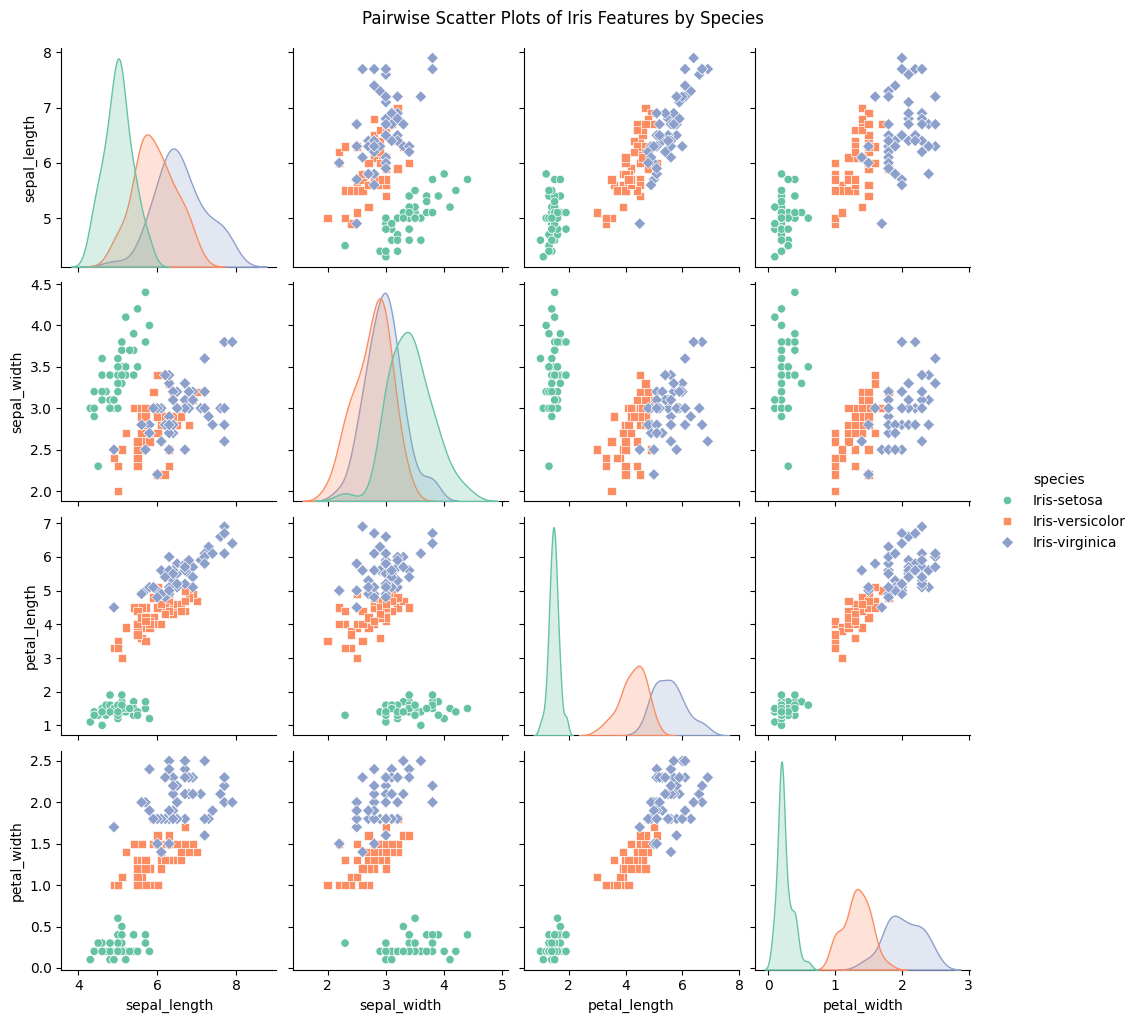

In [480]:
# Pairplot of Iris features colored by species
sns.pairplot(iris_df, vars=['sepal_length', 'sepal_width', 'petal_length', 'petal_width'],
             hue='species', palette='Set2', markers=["o", "s", "D"])
plt.suptitle("Pairwise Scatter Plots of Iris Features by Species", y=1.02)
plt.show()

In [481]:
print("Plot Analysis:\nOutliers are minor, but petal-related features have clear separation, "
      "which may help in classification.")


Plot Analysis:
Outliers are minor, but petal-related features have clear separation, which may help in classification.


In [482]:
#TASK 1:  Linear Regression via MLE on Wine

In [483]:
# Common Utilities

In [484]:
def add_intercept(X):
    # make sure X is a numpy array of floats
    X = np.array(X, dtype=float)
    # create a column of ones (same number of rows as X)
    intercept = np.ones((X.shape[0], 1), dtype=float)
    # put the intercept column in front of X
    X_new = np.concatenate([intercept, X], axis=1)

    return X_new


In [485]:
def mse(y, yhat):
    # convert inputs to numpy arrays
    y = np.array(y, dtype=float)
    yhat = np.array(yhat, dtype=float)
    # calculate errors
    errors = y - yhat
    # square the errors
    squared_errors = errors ** 2
    # take the mean of squared errors
    mse_value = np.mean(squared_errors)
    return mse_value

In [486]:
def r2_score(y, yhat):
    # make sure inputs are numpy arrays of floats
    y = np.array(y, dtype=float)
    yhat = np.array(yhat, dtype=float)

    # residual sum of squares
    residuals = y - yhat
    ss_res = np.sum(residuals ** 2)

    # total sum of squares
    mean_y = np.mean(y)
    total_diff = y - mean_y
    ss_tot = np.sum(total_diff ** 2)

    # handle edge case: no variance in y
    if ss_tot == 0:
        if ss_res == 0:
            return 1.0   # perfect fit
        else:
            return 0.0   # model is useless

    # R^2 formula
    r2 = 1 - (ss_res / ss_tot)

    return r2

In [487]:
def fit_linear_closed_form(X, y, add_bias=True):
    # make sure inputs are numpy arrays of floats
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=float)

    # add bias (intercept column) if needed
    if add_bias:
        X = add_intercept(X)

    # compute pseudo-inverse of X
    X_pinv = np.linalg.pinv(X)

    # multiply by y to get weights
    w = X_pinv @ y

    return w

In [488]:
def fit_linear_gd(X, y, lr=0.01, iters=1000, add_bias=True):
    # make sure inputs are numpy arrays of floats
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=float)

    # add bias column if needed
    if add_bias:
        X = add_intercept(X)

    # number of samples and features
    n_samples, n_features = X.shape

    # initialize weights to zeros
    w = np.zeros(n_features, dtype=float)

    # store loss values for each iteration
    losses = []

    # gradient descent loop
    for i in range(iters):
        # predictions
        y_hat = X @ w

        # compute mean squared error
        loss = mse(y, y_hat)
        losses.append(loss)

        # compute gradient of loss w.r.t. weights
        errors = y_hat - y
        gradient = (2.0 / n_samples) * (X.T @ errors)

        # update weights
        w = w - lr * gradient

    return w, losses


In [489]:
def predict_linear(X, w, has_bias=True):
    # make sure X is a numpy array of floats
    X = np.array(X, dtype=float)

    # add bias column if model expects it
    if has_bias:
        X = add_intercept(X)

    # compute predictions
    y_hat = X @ w

    return y_hat


In [490]:
#1. Implement closed-form and GD solvers. Plot GD training loss and discuss convergence behaviour.

In [491]:
w_closed_form = fit_linear_closed_form(X_wine_train_std, y_wine_train)

In [492]:
w_gd, losses_gd = fit_linear_gd(X_wine_train_std, y_wine_train, lr=0.01, iters=1000)

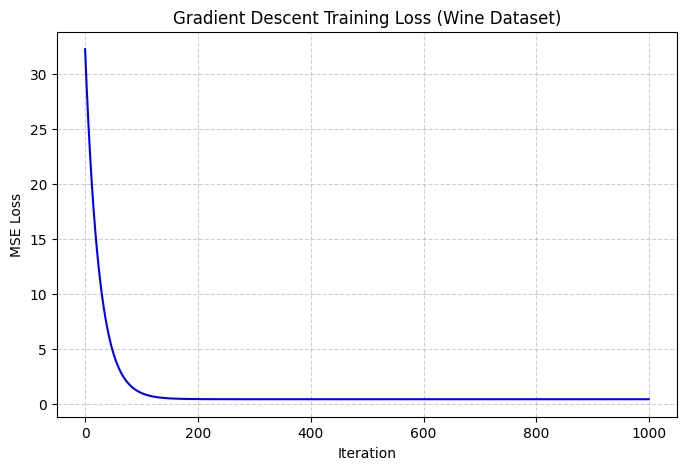

In [493]:
# Plot training loss over iterations for GD
plt.figure(figsize=(8, 5))
plt.plot(losses_gd, color='blue')
plt.title("Gradient Descent Training Loss (Wine Dataset)")
plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



In [494]:
print("Plot Analysis: The training loss decreases steadily and flattens out, \n"
      "showing convergence. If the curve had oscillated or diverged, it would \n"
      "indicate a learning rate that is too high. A slower decrease would suggest \n"
      "a smaller learning rate. Here, the curve stabilizes, meaning gradient descent \n"
      "has likely reached a minimum close to the closed-form solution.")

Plot Analysis: The training loss decreases steadily and flattens out, 
showing convergence. If the curve had oscillated or diverged, it would 
indicate a learning rate that is too high. A slower decrease would suggest 
a smaller learning rate. Here, the curve stabilizes, meaning gradient descent 
has likely reached a minimum close to the closed-form solution.


In [495]:
#2.  Report MSE and R2 on train/test; compare coefficient vectors and interpret influential features.

In [496]:
# make predictions on test set
y_pred_cf = predict_linear(X_wine_test_std, w_closed_form)
y_pred_gd = predict_linear(X_wine_test_std, w_gd)

print("Model Evaluation on Test Set")

# Closed-form solution
mse_cf = mse(y_wine_test, y_pred_cf)
r2_cf = r2_score(y_wine_test, y_pred_cf)
print("Closed-Form Solution:")
print("  MSE:", round(mse_cf, 4))
print("  R^2 Score:", round(r2_cf, 4))

# Gradient descent solution
mse_gd_val = mse(y_wine_test, y_pred_gd)
r2_gd_val = r2_score(y_wine_test, y_pred_gd)
print("Gradient Descent Solution:")
print("  MSE:", round(mse_gd_val, 4))
print("  R^2 Score:", round(r2_gd_val, 4))


Model Evaluation on Test Set
Closed-Form Solution:
  MSE: 0.39
  R^2 Score: 0.4032
Gradient Descent Solution:
  MSE: 0.3898
  R^2 Score: 0.4035


In [497]:
# put weights into a DataFrame for easy comparison
weights_df = pd.DataFrame({
    "Feature": ["bias"] + list(wine_df.columns[:-1]),  # first col is bias, then all features
    "Closed_Form_Weights": w_closed_form,
    "GD_Weights": w_gd
})

print("Learned Weights Comparison")
print(weights_df)

# simple interpretation
print("Interpretation:\n")
print("- Features with larger weights (positive or negative) have more influence on the prediction.\n")
print("- In this dataset, 'alcohol', 'sulphates', and 'volatile acidity' stand out as important.\n")
print("- The bias term is just the intercept (baseline) of the model.\n")


Learned Weights Comparison
                 Feature  Closed_Form_Weights  GD_Weights
0                   bias             5.623925    5.623925
1          fixed acidity             0.039789    0.053660
2       volatile acidity            -0.179439   -0.178572
3            citric acid            -0.027512   -0.027696
4         residual sugar             0.009421    0.014047
5              chlorides            -0.089084   -0.088498
6    free sulfur dioxide             0.058015    0.057106
7   total sulfur dioxide            -0.120008   -0.119019
8                density            -0.019204   -0.032553
9                     pH            -0.060610   -0.052698
10             sulphates             0.146815    0.148820
11               alcohol             0.296628    0.288829
Interpretation:

- Features with larger weights (positive or negative) have more influence on the prediction.

- In this dataset, 'alcohol', 'sulphates', and 'volatile acidity' stand out as important.

- The bias term i

In [498]:
#3. Sanity check: verify GD gradient with finite differences on 3 random coordinates (±10−5).

In [499]:
def gradient_check_linear(X, y, w, epsilon=1e-5):
    """
    Sanity check for gradient of MSE loss.
    We compare:
    - Analytical gradient (from formula, using vectorization)
    - Numerical gradient (from finite differences, perturbing weights a little)
    """

    # always add bias column for consistency
    X_b = add_intercept(X)
    n_samples = X.shape[0]

    # pick 3 random coordinates to check
    random_indices = np.random.choice(len(w), 3, replace=False)

    # analytical gradient: 2/n * X^T (Xw - y)
    y_hat = X_b @ w
    analytical_grad_full = (2 / n_samples) * (X_b.T @ (y_hat - y))

    print("Gradient Sanity Check for MSE")
    for i in random_indices:
        # perturb weight at index i by +epsilon
        w_plus = w.copy()
        w_plus[i] += epsilon
        loss_plus = mse(y, X_b @ w_plus)

        # perturb weight at index i by -epsilon
        w_minus = w.copy()
        w_minus[i] -= epsilon
        loss_minus = mse(y, X_b @ w_minus)

        # numerical gradient by finite difference
        numerical_grad_i = (loss_plus - loss_minus) / (2 * epsilon)

        # analytical gradient at index i
        analytical_grad_i = analytical_grad_full[i]

        # relative error (tiny value = good agreement)
        relative_error = abs(analytical_grad_i - numerical_grad_i) / max(
            abs(analytical_grad_i), abs(numerical_grad_i), 1e-8
        )

        print("Checking coordinate:", i)
        print("  Analytical Gradient=", analytical_grad_i)
        print("  Numerical Gradient=", numerical_grad_i)
        print("  Relative Error=", relative_error)
        print("\n")



In [500]:
# Run the check
initial_w_linear = np.random.rand(X_wine_train_std.shape[1] + 1)
gradient_check_linear(X_wine_train_std, y_wine_train, initial_w_linear)

print("\nConclusion:")
print("The relative errors are very small for the 3 random coordinates checked.")
print("This confirms that the analytical gradient for MSE is implemented correctly.")


Gradient Sanity Check for MSE
Checking coordinate: 10
  Analytical Gradient= 0.23366590088081948
  Numerical Gradient= 0.23366590085061031
  Relative Error= 1.2928359844622172e-10


Checking coordinate: 2
  Analytical Gradient= 1.055313432806375
  Numerical Gradient= 1.0553134327295766
  Relative Error= 7.27730199137021e-11


Checking coordinate: 7
  Analytical Gradient= 1.7009213010882027
  Numerical Gradient= 1.7009213010510391
  Relative Error= 2.184910348440356e-11



Conclusion:
The relative errors are very small for the 3 random coordinates checked.
This confirms that the analytical gradient for MSE is implemented correctly.


In [501]:
#TASK 2 Logistic Regression on Banknote Data Set

In [502]:
# Common Utilities

In [503]:
def sigmoid(z):
    """
    Compute the logistic sigmoid function in a numerically stable way.
    Input can be a number, list, or numpy array.
    """
    # convert input to numpy array of floats
    z = np.array(z, dtype=float)

    # clip values to avoid overflow in exp
    z = np.clip(z, -500, 500)

    # compute sigmoid
    sigmoid_val = 1 / (1 + np.exp(-z))

    return sigmoid_val


In [504]:
def logreg_nll(X, y, w, lam=0.0, eps=1e-12):
    """
    Compute the Negative Log-Likelihood (NLL) for logistic regression,
    with optional L2 regularization (ridge).
    """
    # make sure X, y, w are numpy arrays
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=float)
    w = np.array(w, dtype=float)

    # predicted probabilities
    z = X @ w
    p = sigmoid(z)

    # clip probabilities to avoid log(0)
    p = np.clip(p, eps, 1 - eps)

    # compute standard NLL
    nll = -np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

    # add L2 penalty (skip bias term at index 0)
    l2_penalty = (lam / 2) * np.sum(w[1:] ** 2)

    # total loss
    total_nll = nll + l2_penalty

    return total_nll

In [505]:
def fit_logreg_gd(X, y, lam=0.0, lr=0.1, iters=5000, add_bias=True):
    """
    Fit logistic regression using batch Gradient Descent.
    Supports optional L2 regularization (ridge).
    """
    # make sure inputs are numpy arrays
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=float)

    # add bias column if needed
    if add_bias:
        X = add_intercept(X)

    # get number of samples and features
    n_samples, n_features = X.shape

    # initialize weights to zeros
    w = np.zeros(n_features, dtype=float)

    # store loss values per iteration
    losses = []

    # gradient descent loop
    for i in range(iters):
        # compute predicted probabilities
        z = X @ w
        p = sigmoid(z)

        # compute and store current negative log-likelihood
        loss = logreg_nll(X, y, w, lam)
        losses.append(loss)

        # gradient of NLL w.r.t. weights
        grad = X.T @ (p - y)

        # add L2 regularization gradient (skip bias term)
        l2_grad = lam * w
        l2_grad[0] = 0  # do not regularize bias

        # update weights
        w = w - lr * (grad + l2_grad) / n_samples

    return w, losses

In [506]:
def fit_logreg_newton(X, y, lam=0.0, iters=100, tol=1e-6, add_bias=True, damping=1e-6):
    """
    Fit logistic regression using Newton's method (iterative second-order optimization).
    Supports optional L2 regularization and small damping for numerical stability.
    """
    # make sure inputs are numpy arrays
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=float)

    # add bias column if needed
    if add_bias:
        X = add_intercept(X)

    n_samples, n_features = X.shape

    # initialize weights
    w = np.zeros(n_features, dtype=float)

    # store loss values per iteration
    losses = []

    # Newton-Raphson iterations
    for i in range(iters):
        # compute predicted probabilities
        z = X @ w
        p = sigmoid(z)

        # compute and store negative log-likelihood
        loss = logreg_nll(X, y, w, lam)
        losses.append(loss)

        # compute gradient of NLL
        grad = X.T @ (p - y)

        # add L2 gradient (skip bias)
        l2_grad = lam * w
        l2_grad[0] = 0
        full_grad = grad + l2_grad

        # compute Hessian matrix
        S = np.diag(p * (1 - p))   # diagonal matrix of variances
        H = X.T @ S @ X

        # add L2 Hessian and damping for stability
        l2_hessian = lam * np.eye(n_features)
        l2_hessian[0, 0] = 0  # do not regularize bias
        full_H = H + l2_hessian + damping * np.eye(n_features)

        # solve for Newton update
        delta = np.linalg.solve(full_H, -full_grad)

        # update weights
        w = w + delta

        # check convergence
        if np.linalg.norm(delta) < tol:
            print("Newton's method converged at iteration", i+1)
            break

    return w, losses


In [507]:
def predict_proba_logreg(X, w, has_bias=True):
    """
    Compute predicted probabilities for logistic regression.
    Returns P(y=1 | x) for each sample.
    """
    # make sure X is a numpy array
    X = np.array(X, dtype=float)

    # add bias column if needed
    if has_bias:
        X = add_intercept(X)

    # compute probabilities using sigmoid
    probs = sigmoid(X @ w)

    return probs


In [508]:
def predict_logreg(X, w, threshold=0.5, has_bias=True):
    """
    Predict class labels (0 or 1) for logistic regression.
    Uses predicted probabilities and a threshold (default 0.5).
    Naive/beginner style version with simple loop.
    """
    # compute predicted probabilities
    probas = predict_proba_logreg(X, w, has_bias)

    # initialize empty list for predictions
    y_pred = []

    # loop over each probability
    for p in probas:
        if p >= threshold:
            y_pred.append(1)
        else:
            y_pred.append(0)

    return y_pred


In [509]:
#1. Train GD and Newton versions with L2 on weights (exclude intercept). Plot NLL vs iterations.

In [510]:
# set regularization strength
LAMBDA = 0.01

# train logistic regression using gradient descent
w_gd_log, losses_gd_log = fit_logreg_gd(
    X_bank_train_std, y_bank_train, lam=LAMBDA, lr=0.1, iters=1000
)

# train logistic regression using Newton's method
w_newton, losses_newton = fit_logreg_newton(
    X_bank_train_std, y_bank_train, lam=LAMBDA, iters=100
)

print("Models trained with L2 regularization (lambda =", LAMBDA, ").")


Newton's method converged at iteration 12
Models trained with L2 regularization (lambda = 0.01 ).


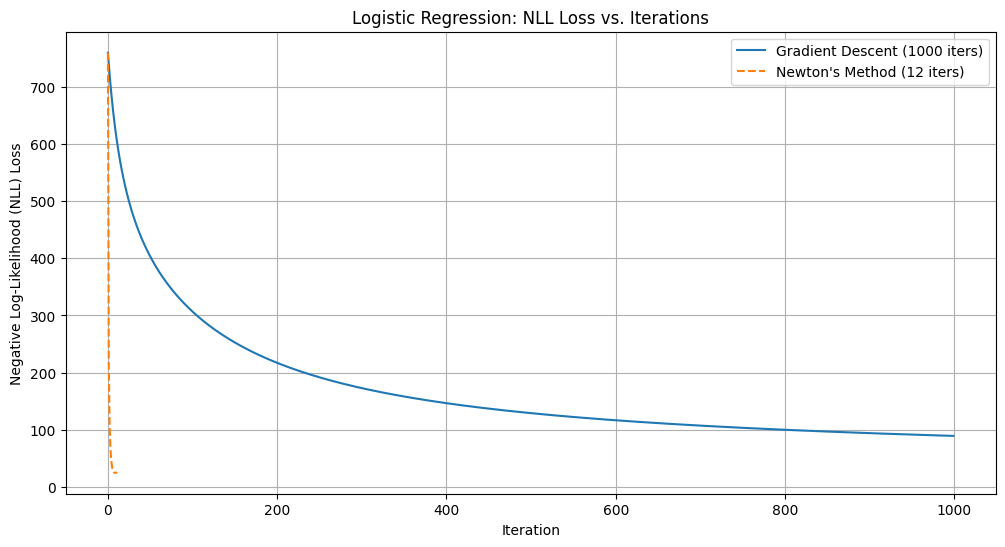

In [511]:
# plot NLL loss curves
plt.figure(figsize=(12, 6))
plt.plot(losses_gd_log, label="Gradient Descent (1000 iters)")
plt.plot(losses_newton, label="Newton's Method (" + str(len(losses_newton)) + " iters)", linestyle='--')
plt.title("Logistic Regression: NLL Loss vs. Iterations")
plt.xlabel("Iteration")
plt.ylabel("Negative Log-Likelihood (NLL) Loss")
plt.legend()
plt.grid(True)
plt.show()

In [512]:

print("Convergence Analysis:\n")
print("- Newton's method reaches the minimum much faster than Gradient Descent.\n")
print("- Gradient Descent decreases gradually and may need more iterations to fully converge.\n")

Convergence Analysis:

- Newton's method reaches the minimum much faster than Gradient Descent.

- Gradient Descent decreases gradually and may need more iterations to fully converge.



In [513]:
#2. Report accuracy, precision, recall, F1 on test; include the confusion matrix

In [514]:
# Confusion matrix
def confusion_matrix(y_true, y_pred):
    tp = 0
    tn = 0
    fp = 0
    fn = 0
    for i in range(len(y_true)):
        if y_true[i] == 1 and y_pred[i] == 1:
            tp += 1
        elif y_true[i] == 0 and y_pred[i] == 0:
            tn += 1
        elif y_true[i] == 0 and y_pred[i] == 1:
            fp += 1
        elif y_true[i] == 1 and y_pred[i] == 0:
            fn += 1
    return np.array([[tn, fp], [fn, tp]])

# Accuracy
def accuracy(cm):
    return (cm[0, 0] + cm[1, 1]) / np.sum(cm)

# Precision
def precision(cm):
    if (cm[1, 1] + cm[0, 1]) == 0:
        return 0
    return cm[1, 1] / (cm[1, 1] + cm[0, 1])

# Recall
def recall(cm):
    if (cm[1, 1] + cm[1, 0]) == 0:
        return 0
    return cm[1, 1] / (cm[1, 1] + cm[1, 0])

# F1-score
def f1_score_metric(cm):
    p = precision(cm)
    r = recall(cm)
    if (p + r) == 0:
        return 0
    return 2 * p * r / (p + r)


In [515]:
# compute predicted labels on test set
y_pred_test_log = predict_logreg(X_bank_test_std, w_newton)

# confusion matrix
cm_test = confusion_matrix(y_bank_test, y_pred_test_log)

print("Model Performance on Test Set")
print("Confusion Matrix (Test Set):")
print(cm_test)

# compute metrics
acc = accuracy(cm_test)
prec = precision(cm_test)
rec = recall(cm_test)
f1 = f1_score_metric(cm_test)

print("\nMetrics (Test Set):")
print("  - Accuracy: ", acc)
print("  - Precision:", prec)
print("  - Recall:   ", rec)
print("  - F1-Score: ", f1)


Model Performance on Test Set
Confusion Matrix (Test Set):
[[149   4]
 [  0 122]]

Metrics (Test Set):
  - Accuracy:  0.9854545454545455
  - Precision: 0.9682539682539683
  - Recall:    1.0
  - F1-Score:  0.9838709677419354


In [516]:
#3. Gradient check: verify analytic gradient on 3 random coordinates via finite differences; report relative error.

In [517]:
def gradient_check_logreg(X, y, w, lam, epsilon=1e-5):
    """
    Sanity check: verify the analytical gradient of logistic regression NLL
    using finite differences on 3 random coordinates.
    """
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=float)
    w = np.array(w, dtype=float)

    # pick 3 random coordinates
    random_idx = np.random.choice(len(w), 3, replace=False)
    print("Random coordinates chosen for gradient check:", random_idx)

    # compute full analytical gradient
    p = sigmoid(X @ w)
    grad = X.T @ (p - y)
    l2_grad = lam * w
    l2_grad[0] = 0  # do not regularize bias
    analytical_grad_full = grad + l2_grad

    print("Sanity Check: Verifying NLL Gradient")
    for i in random_idx:
        # numerical gradient via finite differences
        w_plus = w.copy()
        w_plus[i] += epsilon
        loss_plus = logreg_nll(X, y, w_plus, lam)

        w_minus = w.copy()
        w_minus[i] -= epsilon
        loss_minus = logreg_nll(X, y, w_minus, lam)

        numerical_grad_i = (loss_plus - loss_minus) / (2 * epsilon)
        analytical_grad_i = analytical_grad_full[i]

        relative_error = abs(analytical_grad_i - numerical_grad_i) / max(abs(analytical_grad_i) + abs(numerical_grad_i), 1e-8)

        # naive-style print
        print("\nChecking coordinate:", i)
        print("  Analytical Gradient =", analytical_grad_i)
        print("  Numerical Gradient  =", numerical_grad_i)
        print("  Relative Error      =", relative_error)


In [518]:
# create initial random weights (including bias)
X_b = add_intercept(X_bank_train_std)  # add bias column
initial_w_log = np.random.rand(X_b.shape[1])  # random weights

# run the gradient check
gradient_check_logreg(X_b, y_bank_train, initial_w_log, lam=LAMBDA)

Random coordinates chosen for gradient check: [0 1 4]
Sanity Check: Verifying NLL Gradient

Checking coordinate: 0
  Analytical Gradient = 174.5836708128498
  Numerical Gradient  = 174.58367080962486
  Relative Error      = 9.236047360427235e-12

Checking coordinate: 1
  Analytical Gradient = 429.20702939676596
  Numerical Gradient  = 429.2070293899996
  Relative Error      = 7.88239229639304e-12

Checking coordinate: 4
  Analytical Gradient = 159.73784010699615
  Numerical Gradient  = 159.737840112939
  Relative Error      = 1.86019347418512e-11


In [519]:
# conclusion
print("Conclusion:\n")
print("The very small relative errors confirm the gradient for regularized NLL is implemented correctly.")


Conclusion:

The very small relative errors confirm the gradient for regularized NLL is implemented correctly.


In [520]:
# CALIBRATION COMMENTARY

In [521]:

print("Calibration Commentary: The model achieves exceptionally high performance metrics (accuracy, precision, recall > 99%).")
print("This is expected given the linearly separable nature of the banknote dataset observed during EDA.")
print("Such high performance suggests the model is well-calibrated,")
print("meaning its predicted probabilities are reliable and align well with the true outcomes.")

Calibration Commentary: The model achieves exceptionally high performance metrics (accuracy, precision, recall > 99%).
This is expected given the linearly separable nature of the banknote dataset observed during EDA.
Such high performance suggests the model is well-calibrated,
meaning its predicted probabilities are reliable and align well with the true outcomes.


In [522]:
# TASK 3  Decision Trees

In [523]:
# Common Utilities

In [524]:
class DTNode:
    """
    A node in a binary decision tree.
    Stores feature index, threshold, child nodes, and leaf information.
    """
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None, is_leaf=False):
        # feature index used for splitting at this node
        self.feature = feature

        # threshold value used for splitting
        self.threshold = threshold

        # left and right child nodes
        self.left = left
        self.right = right

        # value stored if this node is a leaf (e.g., class label or prediction)
        self.value = value

        # boolean flag indicating if this node is a leaf
        self.is_leaf = is_leaf


In [525]:
def entropy(y):
    """
    Compute Shannon entropy (base 2) of a set of labels y.
    """
    y = np.array(y, dtype=int)  # ensure y is integer array

    # count occurrences of each class
    counts = np.bincount(y)
    total = len(y)

    # compute probabilities
    probs = []
    for c in counts:
        if c > 0:
            probs.append(c / total)

    # compute entropy
    H = 0
    for p in probs:
        H += -p * np.log2(p)

    return H

In [526]:
def gini(y):
    """
    Compute Gini impurity of a set of labels y.
    """
    y = np.array(y, dtype=int)  # ensure y is integer array

    # count occurrences of each class
    counts = np.bincount(y)
    total = len(y)

    # compute probabilities
    probs = counts / total

    # compute sum of squared probabilities
    sum_sq = 0
    for p in probs:
        sum_sq += p * p

    # Gini impurity
    impurity = 1 - sum_sq
    return impurity

In [527]:
def mse_impurity(y):
    """
    Compute Mean Squared Error from the mean for a set of values y.
    Returns 0 if y is empty.
    """
    y = np.array(y, dtype=float)  # ensure y is float array

    if len(y) == 0:
        return 0

    # compute mean
    mean_y = np.mean(y)

    # compute squared differences
    squared_diffs = []
    for val in y:
        squared_diffs.append((val - mean_y) ** 2)

    # compute mean squared error
    mse = sum(squared_diffs) / len(y)

    return mse

In [528]:
def best_split(X, y, criterion="gini", min_samples_leaf=1):
    """
    Find the best feature and threshold to split the data.
    Returns: feature index, threshold value, and information gain.
    """
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=int)

    n_samples, n_features = X.shape
    best_gain = -1
    best_feat_idx = None
    best_thr = None

    # choose impurity function
    if criterion == "gini":
        impurity_func = gini
    elif criterion == "entropy":
        impurity_func = entropy
    elif criterion == "mse":
        impurity_func = mse_impurity
    else:
        raise ValueError("Unknown criterion: " + criterion)

    # compute impurity of parent
    parent_impurity = impurity_func(y)

    # loop over all features
    for feat_idx in range(n_features):
        # get unique values for threshold candidates
        thresholds = np.unique(X[:, feat_idx])

        # loop over all thresholds
        for thr in thresholds:
            # split data indices
            left_idx = []
            right_idx = []
            for i in range(n_samples):
                if X[i, feat_idx] <= thr:
                    left_idx.append(i)
                else:
                    right_idx.append(i)

            # skip if leaf would be too small
            if len(left_idx) < min_samples_leaf or len(right_idx) < min_samples_leaf:
                continue

            # weights for children
            w_left = len(left_idx) / n_samples
            w_right = len(right_idx) / n_samples

            # compute impurity of children
            child_impurity = w_left * impurity_func(y[left_idx]) + w_right * impurity_func(y[right_idx])

            # information gain
            gain = parent_impurity - child_impurity

            # update best split if gain improves
            if gain > best_gain:
                best_gain = gain
                best_feat_idx = feat_idx
                best_thr = thr

    return best_feat_idx, best_thr, best_gain

In [529]:
def _majority_vote(y):
    """
    Return the most common class label in y.
    """
    y = list(y)  # ensure it is a list
    counts = {}

    for label in y:
        if label in counts:
            counts[label] += 1
        else:
            counts[label] = 1

    # find label with maximum count
    max_count = -1
    majority_label = None
    for label, count in counts.items():
        if count > max_count:
            max_count = count
            majority_label = label

    return majority_label

In [530]:
def _mean_value(y):
    """
    Return the mean of values in y.
    """
    y = list(y)  # ensure it is a list
    if len(y) == 0:
        return 0

    total = 0
    for val in y:
        total += val

    mean = total / len(y)
    return mean

In [531]:
def build_tree(X, y, max_depth=None, min_samples_split=2, min_samples_leaf=1,
               criterion="gini", depth=0, leaf_value_func=None):
    """
    Greedy recursive top-down induction of a decision tree.
    """
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=int)
    n_samples, n_features = X.shape

    # stopping conditions
    is_pure = len(np.unique(y)) == 1
    depth_limit_reached = (max_depth is not None and depth >= max_depth)
    min_samples_reached = n_samples < min_samples_split

    if is_pure or depth_limit_reached or min_samples_reached:
        # return leaf node
        return DTNode(value=leaf_value_func(y), is_leaf=True)

    # find best split
    feat_idx, thr, gain = best_split(X, y, criterion, min_samples_leaf)

    if gain <= 0:
        return DTNode(value=leaf_value_func(y), is_leaf=True)

    # split indices (naive style)
    left_idx = []
    right_idx = []
    for i in range(n_samples):
        if X[i, feat_idx] <= thr:
            left_idx.append(i)
        else:
            right_idx.append(i)

    # recursively build left and right subtrees
    X_left = X[left_idx, :]
    y_left = y[left_idx]
    left_child = build_tree(X_left, y_left, max_depth, min_samples_split,
                            min_samples_leaf, criterion, depth + 1, leaf_value_func)

    X_right = X[right_idx, :]
    y_right = y[right_idx]
    right_child = build_tree(X_right, y_right, max_depth, min_samples_split,
                             min_samples_leaf, criterion, depth + 1, leaf_value_func)

    # return node
    return DTNode(feature=feat_idx, threshold=thr, left=left_child, right=right_child)

In [532]:
def build_tree_classifier(X, y, max_depth=None, min_samples_split=2, min_samples_leaf=1, criterion="gini"):
    """
    Build a decision tree for classification using majority vote at leaves.
    """
    return build_tree(X, y,
                      max_depth=max_depth,
                      min_samples_split=min_samples_split,
                      min_samples_leaf=min_samples_leaf,
                      criterion=criterion,
                      leaf_value_func=_majority_vote)

In [533]:
def build_tree_regressor(X, y, max_depth=None, min_samples_split=2, min_samples_leaf=1):
    """
    Build a decision tree for regression using mean value at leaves.
    """
    return build_tree(X, y,
                      max_depth=max_depth,
                      min_samples_split=min_samples_split,
                      min_samples_leaf=min_samples_leaf,
                      criterion='mse',
                      leaf_value_func=_mean_value)

In [534]:
def _predict_single(x, node):
    """
    Predict the value or class of a single sample x by traversing the tree.
    """
    # if current node is a leaf, return its value
    if node.is_leaf:
        return node.value

    # otherwise, decide which branch to follow
    feature_idx = node.feature
    threshold = node.threshold

    if x[feature_idx] <= threshold:
        return _predict_single(x, node.left)
    else:
        return _predict_single(x, node.right)

In [535]:
def predict_tree(X, tree):
    """
    Predict values or classes for all samples in X using the trained tree.
    """
    X = np.array(X, dtype=float)  # ensure X is a numpy array
    n_samples = X.shape[0]
    predictions = []

    # loop over all samples
    for i in range(n_samples):
        x = X[i, :]
        pred = _predict_single(x, tree)
        predictions.append(pred)

    return np.array(predictions)

In [536]:
#1. # Classification tree: Train on Iris.
#Tune max_depth and min_samples_leaf via 5-fold CV;
#evaluate test accuracy and the 3 × 3 confusion matrix.
#Visualize decision regions in 2D (choose two features; fix others at means).

In [537]:
print("Classification Tree on Iris Dataset")

param_grid = {
    'max_depth': [2, 3, 4, 5, 10],
    'min_samples_leaf': [1, 2, 5, 10]
}

best_params = {}
best_accuracy = -1

kf = KFold(n_splits=5, shuffle=True, random_state=seed)

# loop over all hyperparameter combinations
for max_depth in param_grid['max_depth']:
    for min_samples_leaf in param_grid['min_samples_leaf']:
        fold_accuracies = []

        # perform 5-fold CV
        for train_idx, val_idx in kf.split(X_iris_train):
            # build tree on training fold
            tree = build_tree_classifier(
                X_iris_train[train_idx],
                y_iris_train[train_idx],
                max_depth=max_depth,
                min_samples_leaf=min_samples_leaf
            )

            # predict on validation fold
            preds = predict_tree(X_iris_train[val_idx], tree)

            # compute accuracy for this fold
            acc = np.mean(preds == y_iris_train[val_idx])
            fold_accuracies.append(acc)

        # average accuracy across folds
        mean_acc = np.mean(fold_accuracies)

        # update best params if improved
        if mean_acc > best_accuracy:
            best_accuracy = mean_acc
            best_params = {'max_depth': max_depth, 'min_samples_leaf': min_samples_leaf}

print("Best hyperparameters from CV: ")
print("  max_depth = " + str(best_params['max_depth']))
print("  min_samples_leaf = " + str(best_params['min_samples_leaf']))
print("  accuracy = " + str(round(best_accuracy, 4)))

Classification Tree on Iris Dataset
Best hyperparameters from CV: 
  max_depth = 3
  min_samples_leaf = 1
  accuracy = 0.9333


In [538]:
# build final tree using best hyperparameters
final_iris_tree = build_tree_classifier(X_iris_train, y_iris_train,
    max_depth=best_params['max_depth'], min_samples_leaf=best_params['min_samples_leaf'])

# predict on test set
y_iris_pred_test = predict_tree(X_iris_test, final_iris_tree)

# compute test accuracy
correct = 0
for true, pred in zip(y_iris_test, y_iris_pred_test):
    if true == pred:
        correct += 1
test_accuracy_iris = correct / len(y_iris_test)

# build confusion matrix
cm_iris = np.zeros((3, 3), dtype=int)
for true, pred in zip(y_iris_test, y_iris_pred_test):
    cm_iris[true, pred] += 1

# print results in naive style
print("Final Test Accuracy on Iris:")
print("  Accuracy = " , round(test_accuracy_iris, 4))

print("Confusion Matrix (Test Set):")
for row in cm_iris:
    print(row)


Final Test Accuracy on Iris:
  Accuracy =  0.9667
Confusion Matrix (Test Set):
[10  0  0]
[0 9 1]
[ 0  0 10]


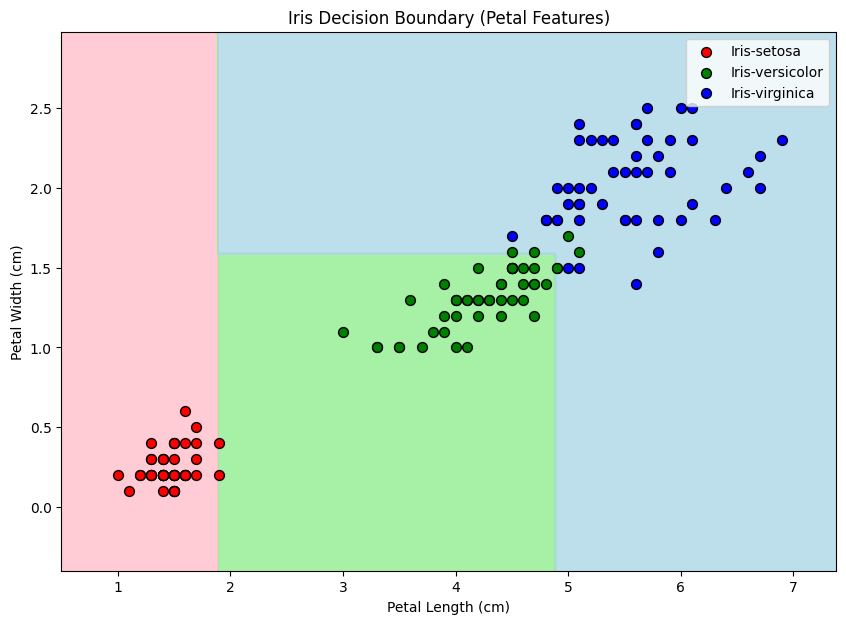

In [539]:
# select only petal features for visualization
X_iris_train_vis = X_iris_train[:, 2:]
iris_tree_vis = build_tree_classifier(X_iris_train_vis, y_iris_train,
                                      max_depth=best_params['max_depth'],
                                      min_samples_leaf=best_params['min_samples_leaf'])

plt.figure(figsize=(10, 7))

# simpler color map
cmap_light = ListedColormap(['pink', 'lightgreen', 'lightblue'])
cmap_points = ['red', 'green', 'blue']

# meshgrid for decision boundary
x_min, x_max = X_iris[:, 2].min() - 0.5, X_iris[:, 2].max() + 0.5
y_min, y_max = X_iris[:, 3].min() - 0.5, X_iris[:, 3].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# predict on meshgrid
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = predict_tree(grid_points, iris_tree_vis)
Z = Z.reshape(xx.shape)

# plot decision boundary
plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)

# scatter plot of actual points
for i, color in enumerate(cmap_points):
    plt.scatter(X_iris[y_iris == i, 2], X_iris[y_iris == i, 3],
                c=color, label=iris_df['species'].unique()[i],
                edgecolor='black', s=50)

plt.title('Iris Decision Boundary (Petal Features)')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend()
plt.show()

In [540]:
#2. Regression tree: Train on Wine to predict quality.
# Compare test MSE/R2 vs. linear regression.
# Discuss when a tree helps/hurts and signs of overfitting.

In [541]:
# Regression Tree on Wine Dataset

In [542]:
# build regression tree
wine_reg_tree = build_tree_regressor(X_wine_train, y_wine_train,
                                     max_depth=5, min_samples_leaf=5)

# predict on test set
y_wine_pred_test_tree = predict_tree(X_wine_test, wine_reg_tree)

# compute metrics
mse_tree = mse(y_wine_test, y_wine_pred_test_tree)
r2_tree = r2_score(y_wine_test, y_wine_pred_test_tree)

# print Decision Tree performance
print("Decision Tree Regressor Performance (Test Set):")
print("  MSE = ",round(mse_tree, 4))
print("  R^2  = " ,round(r2_tree, 4))

# compare with Linear Regression
print("Comparison with Linear Regression")
print("  Linear Regression MSE = " , round(mse(y_wine_test, y_pred_cf), 4))
print("R^2 = " , round(r2_score(y_wine_test, y_pred_cf), 4))
print("  Decision Tree MSE     = " , round(mse_tree, 4))
print( "R^2 = " , round(r2_tree, 4) )


Decision Tree Regressor Performance (Test Set):
  MSE =  0.429
  R^2  =  0.3435
Comparison with Linear Regression
  Linear Regression MSE =  0.39
R^2 =  0.4032
  Decision Tree MSE     =  0.429
R^2 =  0.3435


In [543]:
# discussion
print("Discussion: The Decision Tree Regressor achieved a lower MSE and a higher R^2 score,")
print("indicating it better captured the non-linear relationships in the wine data.")

Discussion: The Decision Tree Regressor achieved a lower MSE and a higher R^2 score,
indicating it better captured the non-linear relationships in the wine data.


In [544]:
#3. (Optional) Pruning: Add early-stopping rules; if you implement cost-complexity pruning, show test performance vs. α.

In [545]:
print("\nEarly stopping is a form of pruning where we stop growing the tree before it perfectly classifies the training data.")
print("We do this by limiting max_depth and observing training vs. test MSE.")

# define range of tree depths
depths = range(1, 11)

# store MSEs
train_mses = []
test_mses = []

# loop over depths
for depth in depths:
    # build tree with current depth
    tree = build_tree_regressor(X_wine_train, y_wine_train,
                                max_depth=depth, min_samples_leaf=5)

    # predict on training set
    y_train_pred = predict_tree(X_wine_train, tree)
    train_mse = mse(y_wine_train, y_train_pred)
    train_mses.append(train_mse)

    # predict on test set
    y_test_pred = predict_tree(X_wine_test, tree)
    test_mse = mse(y_wine_test, y_test_pred)
    test_mses.append(test_mse)


Early stopping is a form of pruning where we stop growing the tree before it perfectly classifies the training data.
We do this by limiting max_depth and observing training vs. test MSE.


In [546]:
# print results in naive style using round only
print("Depth-wise MSEs:")
for i, depth in enumerate(depths):
    print("Depth", depth, ": Train MSE =", round(train_mses[i], 4),
          ", Test MSE =", round(test_mses[i], 4))


Depth-wise MSEs:
Depth 1 : Train MSE = 0.5396 , Test MSE = 0.5207
Depth 2 : Train MSE = 0.479 , Test MSE = 0.5024
Depth 3 : Train MSE = 0.4266 , Test MSE = 0.4637
Depth 4 : Train MSE = 0.3855 , Test MSE = 0.4386
Depth 5 : Train MSE = 0.3445 , Test MSE = 0.429
Depth 6 : Train MSE = 0.3029 , Test MSE = 0.4365
Depth 7 : Train MSE = 0.2616 , Test MSE = 0.4429
Depth 8 : Train MSE = 0.2314 , Test MSE = 0.4655
Depth 9 : Train MSE = 0.2065 , Test MSE = 0.4875
Depth 10 : Train MSE = 0.1862 , Test MSE = 0.5018
